# Lab 3 — Bayes and kNN forest–urban classification

Phases **1–3 are complete**: auditable labelled data, fitted Gaussian class PDFs, and a scratch Bayes classifier applied to the independent Tychy image. Maps, numerical checks and written observations document poor forest transfer: only 148 of 2,304 forest reference pixels are correctly classified. Phases 4–6 remain pending. See [CHECKLIST.md](CHECKLIST.md) and [README.md](README.md).

## 1. Prepare the notebook, labelled data and test image

Acceptance: verify the saved source hashes, calibration, grids and QA; manually select reproducible reference ROIs; separate spatial training/holdout and a new test footprint; save exact balanced training samples and scaling fitted only on those samples. Labels are visual assistant annotations, not field-verified ground truth. No classifier outputs are used to select labels.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'lab3').is_dir() else Path.cwd().parent
assert (ROOT / 'lab3' / 'inputs.py').is_file()
sys.path.insert(0, str(ROOT / 'lab3'))
import inputs as lab3_inputs
print('Project:', ROOT.name, '| kernel:', sys.executable)

Project: MLForSpace | kernel: /Users/molczane/Developer/MLForSpace/.venv/bin/python


### Independent test acquisition

Tychy uses August 2025 (within the training pair's summer window), Sentinel-2 Level-2A Collection 1, native 10 m RGB and the same fixed display mapping. The initial 0.1% local flagged-SCL threshold rejected all candidates. For this mixed urban image the threshold is explicitly 0.25%; every flagged pixel is still excluded by QA. Tile-level cloud cover remains at most 10%. The saved acquisition is verified offline; a download occurs only when its metadata are absent. Source IDs, selection attempts, dates and radiometric conversion remain recorded.

In [2]:
test_metadata = lab3_inputs.acquire_test()
print('Test scene:', test_metadata['scene_id'])
print('Acquired UTC:', test_metadata['acquired_utc'])
print('Local flagged QA fraction:', test_metadata['aoi_bad_fraction'])

Test scene: S2C_T34UCA_20250814T095058_L2A
Acquired UTC: 2025-08-14T09:57:04.138000Z
Local flagged QA fraction: 0.00189208984375


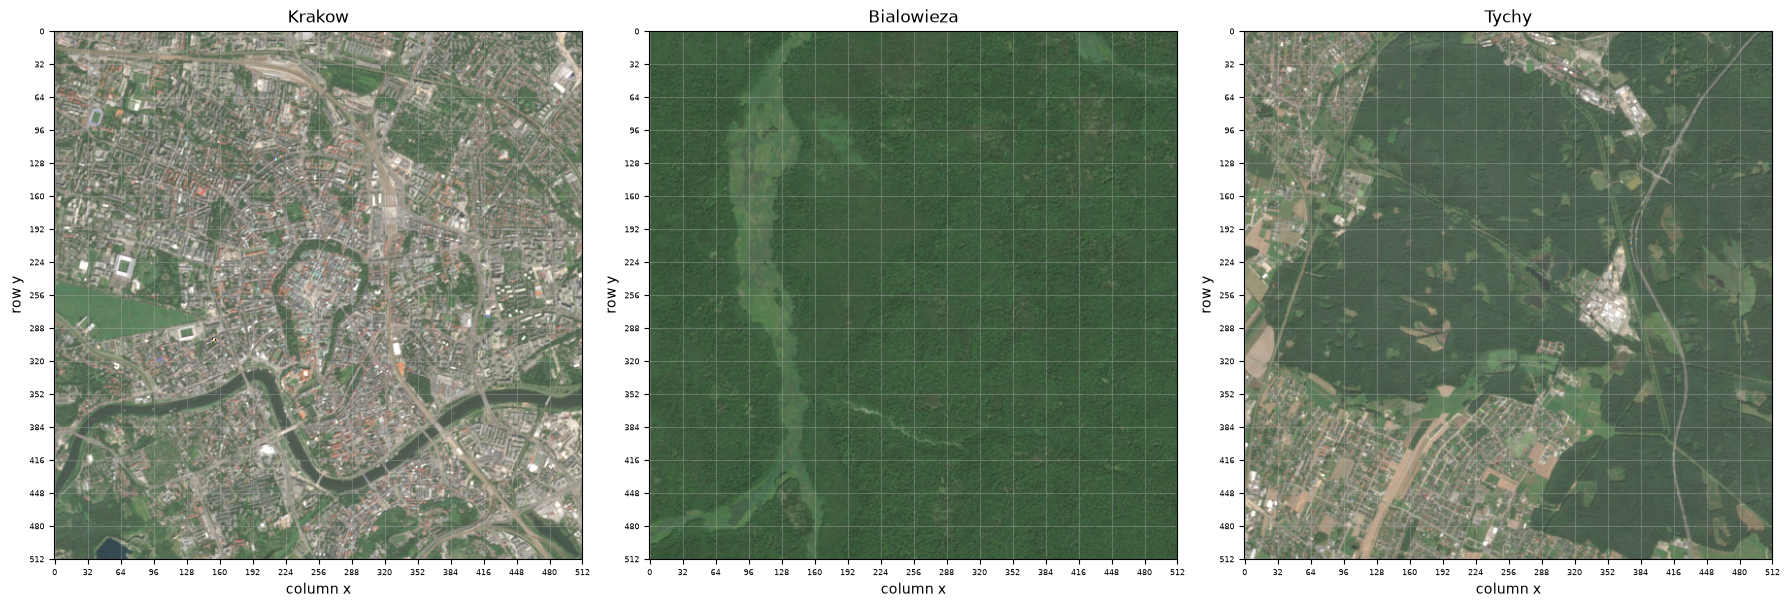

In [3]:
from PIL import Image
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (key, folder) in zip(axes, lab3_inputs.SOURCE_DIRS.items()):
    ax.imshow(Image.open(folder / 'rgb.png'))
    ax.set_title(key.title())
    ax.set_xticks(np.arange(0, 513, 32))
    ax.set_yticks(np.arange(0, 513, 32))
    ax.grid(alpha=.35)
    ax.tick_params(labelsize=6)
    ax.set_xlabel('column x'); ax.set_ylabel('row y')
fig.tight_layout()
plt.show()

### Reference labels, spatial split and sampling

`rois.json` records hand-selected, zero-based, half-open pixel rectangles, their class and split. **Forest (0, red)** means closed-canopy interiors. **Urban (1, blue)** means continuous built-up impervious fabric: roofs, paved streets/courtyards and industrial structures. **255** means unlabelled/uncertain, not a third trained class. These are assistant visual annotations with possible mixed pixels, not independent field surveys. SCL is used only for QA.

Training and spatial holdout patches are disjoint with a 16-pixel (160 m) Chebyshev buffer checked against complete training ROIs. Tychy has a distinct, nonoverlapping footprint and scene ID and contributes no training samples. References avoid obvious fields, water, parks and uncertain boundaries. The independent test annotations are sparse and emphasize clear industrial surfaces; they do not represent all urban land cover. Valid unlabelled pixels will still be forced into one of the two classes by later classifiers.

A PCG64 generator with seed **20261115** selects **512 pixels per class**, without replacement, from the training ROIs. The exact identities and raw feature rows are saved. Both classifiers will use these same 1,024 samples.

In [4]:
sources, label_masks, manifest = lab3_inputs.prepare()
summary = ['| Source | Acquisition UTC | Valid / total | Training ROI pixels F/U | Holdout F/U | Test reference F/U |', '|---|---|---:|---:|---:|---:|']
for key, source in manifest['sources'].items():
    counts = source['counts']
    pairs = [str(counts[split]['forest']) + ' / ' + str(counts[split]['urban']) for split in ('train', 'holdout', 'test')]
    summary.append('| ' + ' | '.join([key, source['acquired_utc'], str(source['valid_pixels']) + ' / 262144', *pairs]) + ' |')
display(Markdown('\n'.join(summary)))
print('Saved exact training arrays, georeferenced QA/reference masks, scaling and source manifest.')

| Source | Acquisition UTC | Valid / total | Training ROI pixels F/U | Holdout F/U | Test reference F/U |
|---|---|---:|---:|---:|---:|
| krakow | 2025-08-13T09:46:56.167000Z | 262064 / 262144 | 0 / 648 | 0 / 252 | 0 / 0 |
| bialowieza | 2025-07-02T09:46:14.474000Z | 262144 / 262144 | 2304 / 0 | 1728 / 0 | 0 / 0 |
| tychy | 2025-08-14T09:57:04.138000Z | 261648 / 262144 | 0 / 0 | 0 / 0 | 2304 / 256 |

Saved exact training arrays, georeferenced QA/reference masks, scaling and source manifest.


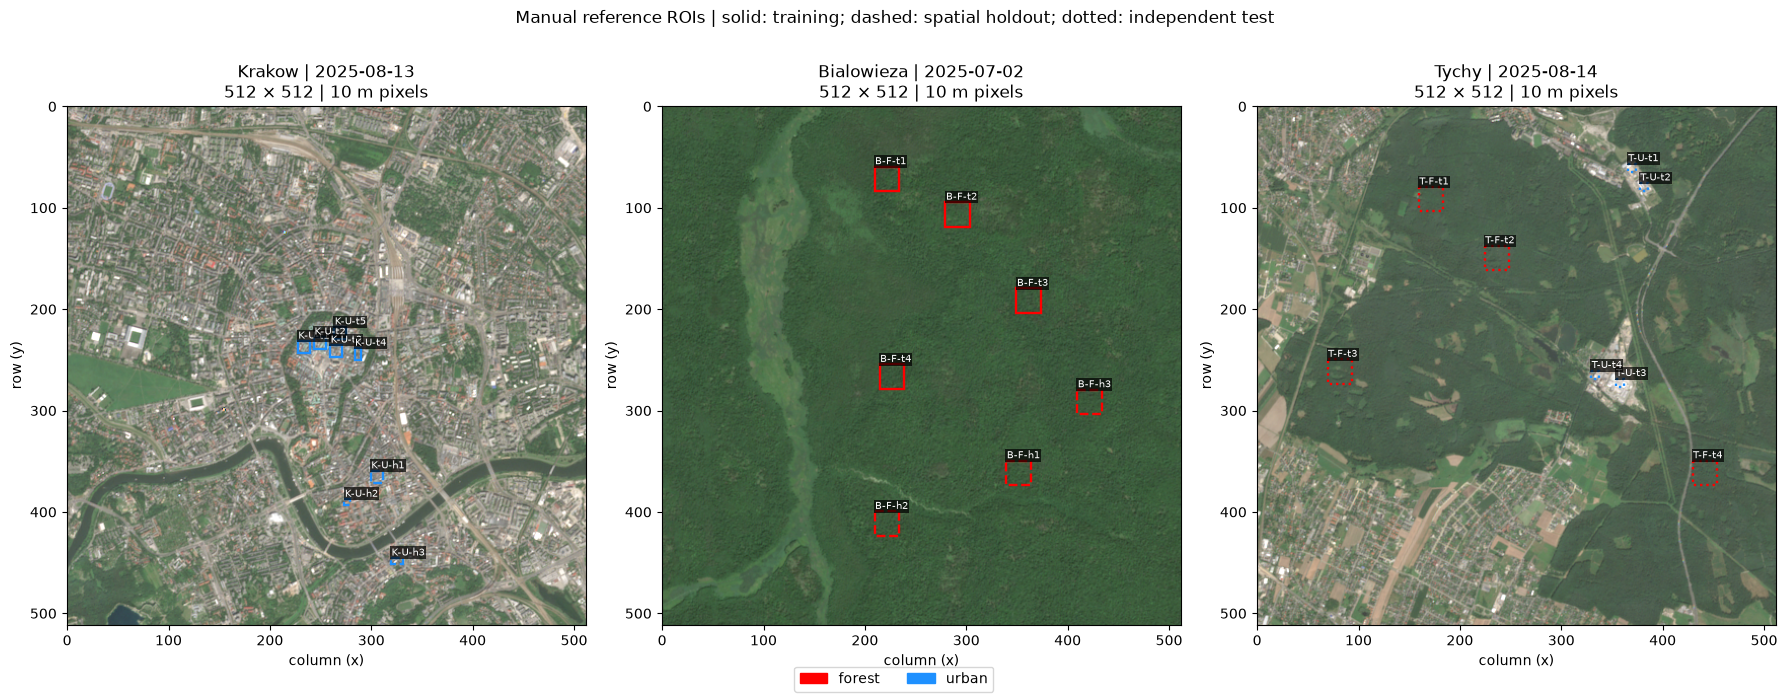

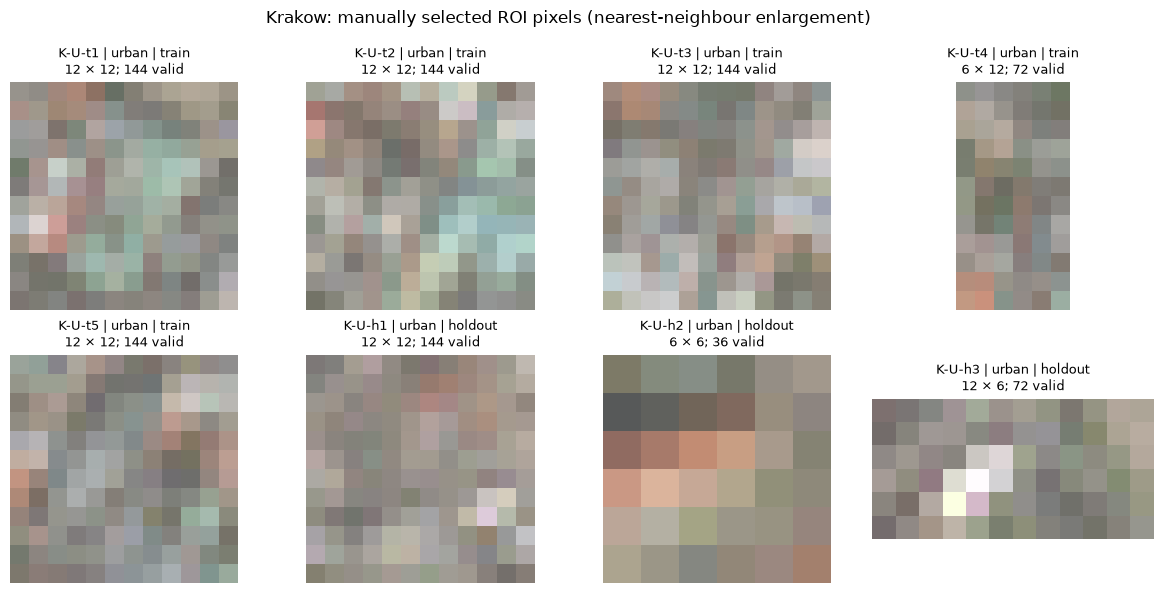

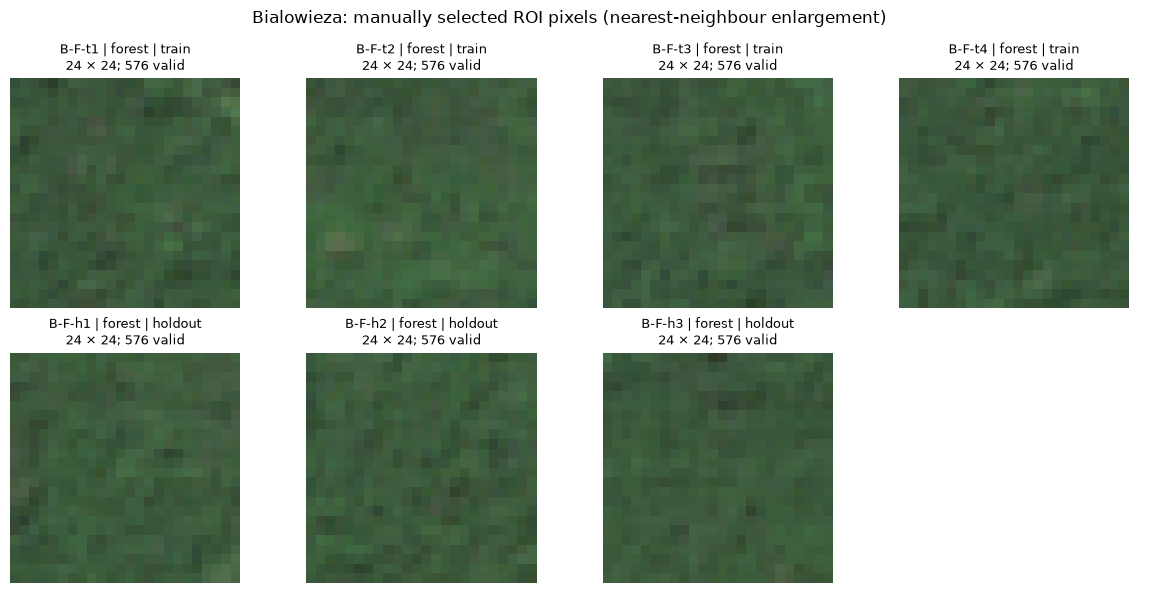

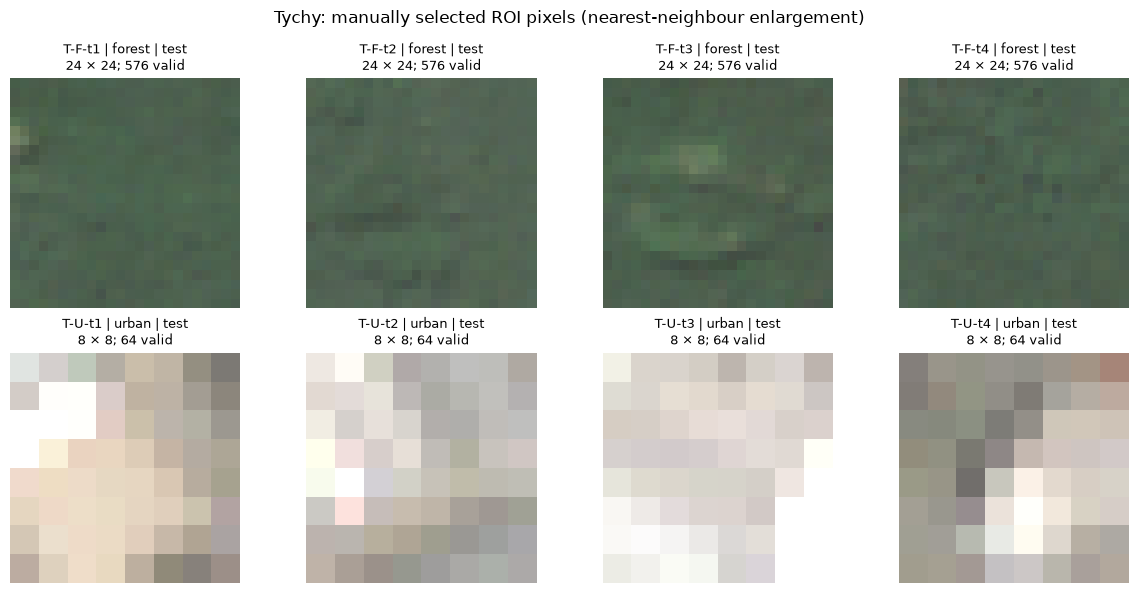

In [5]:
figures = lab3_inputs.overview(sources, label_masks, manifest)
for figure in figures:
    display(figure)
    plt.close(figure)

### Training-only feature scaling and saved arrays

Features are **B04, B03, B02 dimensionless BOA reflectance**, not gamma-corrected display RGB. Original calibration is checked against the source DN and scale/offset. The QA mask excludes nodata, defective pixels, cloud shadow, unclassified pixels, clouds, cirrus and snow, but retains valid dark pixels and negative reflectance. The original Lab 2 masks are checked for exact equality.

Scaling is `z = (x - training_mean) / training_std` with population standard deviation (`ddof=0`), fitted only on the exact 1,024 sampled training rows. Exactly zero standard deviations are replaced by 1. The saved mean/scale are applied unchanged to holdout and test pixels. A QA value of 0 means invalid; label value 255 means no reference annotation. Neither is a land-cover class.

In [6]:
training = np.load(lab3_inputs.DATA / 'training_samples.npz')
X_train, y_train = training['X_scaled'], training['y']
scaling_mean, scaling_scale = training['mean'], training['scale']
print('Training shape:', X_train.shape, '| labels:', np.bincount(y_train))
print('Band order:', lab3_inputs.BANDS)
print('Training mean (reflectance):', scaling_mean)
print('Training scale (reflectance):', scaling_scale)
X_test_raw = np.moveaxis(sources['tychy']['x'], 0, -1)
X_test_scaled = (X_test_raw - scaling_mean) / scaling_scale
assert np.isfinite(X_test_scaled[sources['tychy']['valid']]).all()
print('Transformed test grid:', X_test_scaled.shape, '| no test-derived parameters')

Training shape: (1024, 3) | labels: [512 512]
Band order: ('B04', 'B03', 'B02')
Training mean (reflectance): [0.05538125 0.06279999 0.04884072]
Training scale (reflectance): [0.04798552 0.04011589 0.04238929]
Transformed test grid: (512, 512, 3) | no test-derived parameters


In [7]:
from unittest.mock import patch
with patch('socket.socket.connect', side_effect=RuntimeError('Network disabled for phase-1 audit')), patch('urllib.request.urlopen', side_effect=RuntimeError('Network disabled for phase-1 audit')):
    lab3_inputs.acquire_test()  # verify saved acquisition without remote access
    phase1_verification = lab3_inputs.verify()
phase1_verification['saved_input_audit_network_disabled'] = True
lab3_inputs.dump(lab3_inputs.DATA / 'verification.json', phase1_verification)
print(json.dumps(phase1_verification, indent=2))

{
  "status": "passed",
  "input_and_output_hashes": 37,
  "training_samples": 1024,
  "per_class": [
    512,
    512
  ],
  "feature_count": 3,
  "seed": 20261115,
  "spatial_buffer_pixels": 16,
  "independent_test": "tychy; nonoverlapping footprint and distinct scene ID",
  "versions": {
    "numpy": "2.5.4",
    "rasterio": "1.5.2",
    "pillow": "13.0.0",
    "matplotlib": "3.11.2",
    "scipy": "1.18.1"
  },
  "saved_input_audit_network_disabled": true
}


### Phase 1 interpretation and limitations

The source previews contain substantial non-target cover: Kraków has parks and the Vistula, Białowieża has a river/clearing corridor, and Tychy contains fields as well as forests and buildings. Only the recorded compact reference ROIs receive land-cover labels. The RGB display uses the same reflectance / 0.3, clipped to [0,1], gamma 1/2.2 mapping everywhere; no per-image stretch affects numerical features.

Forest and urban training examples come from different locations and dates. This confounds class with geography/scene conditions; a separate Tychy scene tests transfer but cannot establish general regional accuracy. Visual labels have uncertain subpixel purity. Sparse industrial test references can make evaluation look easier than the entire landscape, and a spatial buffer reduces local leakage without guaranteeing statistical independence. Later metrics must state reference support and these limits.

Phase 1 does not estimate class PDFs or predict classes. Those experiments follow in the sections below.

## 2. Plot class histograms and estimate parametric PDFs

We use the exact **512 forest + 512 urban training rows** saved in phase 1. No held-out or Tychy pixels enter histograms, parameter estimation, regularization selection or priors. Features are B04/B03/B02 BOA reflectance, with the previously saved training-only scaling.

The baseline is a full multivariate Gaussian, $z\mid c\sim\mathcal{N}(\mu_c,\Sigma_c)$, where $z=(x-m)/s$. From scratch, $\hat\mu_c=N_c^{-1}\sum_i z_i$ and $\hat\Sigma_c=N_c^{-1}\sum_i(z_i-\hat\mu_c)(z_i-\hat\mu_c)^T$ (**MLE denominator $N_c$, not $N_c-1$**). We use $\Sigma_c=\hat\Sigma_c+10^{-6}I$ in standardized units, fixed before examining fit diagnostics. The unregularized MLE and regularized model are both retained.

For interpretation in reflectance units, $\mu_{x,c}=m+D\mu_c$ and $\Sigma_{x,c}=D\Sigma_cD$, with $D=\mathrm{diag}(s)$. Thus the regularization adds $10^{-6}s_j^2$ to raw band variance, not a constant $10^{-6}$ reflectance variance. Priors are **$P(\mathrm{forest})=P(\mathrm{urban})=0.5$**, an explicit balanced-comparison assumption; our sampling design does not estimate Tychy's land-cover proportions.

Acceptance checks: all six full-range histograms count every training row and integrate to one; parameters agree with direct raw-unit moments; regularized covariances are positive definite; Gaussian marginals integrate to one; saved CSV/JSON/NPZ values reproduce the training calculations. A Gaussian fit is an assumption, not a normality result or classification accuracy measurement.

### Joint PDF and marginal display

For three standardized features, the fitted class PDF is
$$p(z\mid c)=\frac{\exp\!\left[-\tfrac12(z-\mu_c)^T\Sigma_c^{-1}(z-\mu_c)\right]}{(2\pi)^{3/2}|\Sigma_c|^{1/2}}.$$
Here $\Sigma_c$ is the regularized full covariance. A displayed raw-band marginal is the univariate Gaussian with mean $\mu_{x,c,j}$ and variance $(\Sigma_{x,c})_{jj}$. The six marginal curves are not factors of an independent-band model. Densities expressed in raw and scaled units differ by a Jacobian: $p_x(x\mid c)=p_z((x-m)/s\mid c)/\prod_js_j$. We verify this conversion for each plotted marginal. The common scaling/Jacobian will not change a comparison between classes.

In [8]:
# Explicit Gaussian parameter estimation; no ready-made classifier or PDF fit.
import csv
from scipy.special import ndtr
BANDS = tuple(lab3_inputs.BANDS)
CLASS_NAMES = ('forest', 'urban')
OUT = ROOT / 'lab3' / 'results' / 'bayes'
OUT.mkdir(parents=True, exist_ok=True)
REGULARIZATION = 1e-6
PRIORS = np.array([0.5, 0.5], dtype=np.float64)

def gaussian_mle(samples):
    samples = np.asarray(samples, dtype=np.float64)
    if samples.ndim != 2 or len(samples) < 2 or not np.isfinite(samples).all():
        raise ValueError('Expected at least two finite feature rows')
    mean = samples.mean(axis=0)
    centered = samples - mean
    covariance = centered.T @ centered / len(samples)
    return mean, covariance

def marginal_pdf(points, mean, variance):
    return np.exp(-0.5 * (points - mean)**2 / variance) / np.sqrt(2*np.pi*variance)

X_raw = training['X_raw'].astype(np.float64)
np.testing.assert_allclose(X_train, (X_raw-scaling_mean)/scaling_scale, rtol=0, atol=0)
model = []
sensitivity = []
for label, name in enumerate(CLASS_NAMES):
    raw = X_raw[y_train == label]
    scaled = X_train[y_train == label]
    mean_z, cov_z_mle = gaussian_mle(scaled)
    cov_z = cov_z_mle + REGULARIZATION * np.eye(len(BANDS))
    mean_raw = scaling_mean + scaling_scale * mean_z
    cov_raw_mle = cov_z_mle * np.outer(scaling_scale, scaling_scale)
    cov_raw = cov_z * np.outer(scaling_scale, scaling_scale)
    sd = np.sqrt(np.diag(cov_raw_mle))
    correlation = cov_raw_mle / np.outer(sd, sd)
    model.append(dict(label=label, name=name, n=len(raw), prior=float(PRIORS[label]),
                      mean_z=mean_z, cov_z_mle=cov_z_mle, cov_z=cov_z,
                      mean_raw=mean_raw, cov_raw_mle=cov_raw_mle, cov_raw=cov_raw,
                      correlation=correlation))
    for epsilon in (0.0, 1e-8, REGULARIZATION, 1e-4):
        cov = cov_z_mle + epsilon*np.eye(len(BANDS))
        eig = np.linalg.eigvalsh(cov)
        sensitivity.append(dict(class_name=name, epsilon=epsilon, min_eigenvalue=float(eig[0]),
                                condition_number=float(eig[-1]/eig[0]),
                                max_marginal_variance_increase_percent=float(np.max(100*epsilon/np.diag(cov_z_mle))),
                                max_directional_variance_increase_percent=float(100*epsilon/np.linalg.eigvalsh(cov_z_mle)[0])))
print('Samples:', {m['name']: m['n'] for m in model})
print('Regularization in scaled units:', REGULARIZATION, '| class priors:', PRIORS)
for m in model:
    print('\n' + m['name'].upper() + ' | band order ' + str(BANDS))
    print('Raw reflectance mean:', m['mean_raw'])
    print('Raw MLE covariance [reflectance squared]:\n', m['cov_raw_mle'])
    print('Scaled mean:', m['mean_z'])
    print('Scaled MLE covariance:\n', m['cov_z_mle'])
    print('Scaled regularized covariance:\n', m['cov_z'])
    print('Raw-band correlation:\n', m['correlation'])


Samples: {'forest': 512, 'urban': 512}
Regularization in scaled units: 1e-06 | class priors: [0.5 0.5]

FOREST | band order ('B04', 'B03', 'B02')
Raw reflectance mean: [0.01284668 0.0301957  0.01275507]
Raw MLE covariance [reflectance squared]:
 [[5.42405163e-06 8.84141115e-06 3.99342488e-06]
 [8.84141115e-06 2.69651757e-05 8.18982609e-06]
 [3.99342488e-06 8.18982609e-06 4.67950489e-06]]
Scaled mean: [-0.88640432 -0.81275264 -0.85129154]
Scaled MLE covariance:
 [[0.00235561 0.00459298 0.00196327]
 [0.00459298 0.016756   0.00481617]
 [0.00196327 0.00481617 0.00260428]]
Scaled regularized covariance:
 [[0.00235661 0.00459298 0.00196327]
 [0.00459298 0.016757   0.00481617]
 [0.00196327 0.00481617 0.00260528]]
Raw-band correlation:
 [[1.         0.73106847 0.79265401]
 [0.73106847 1.         0.7290765 ]
 [0.79265401 0.7290765  1.        ]]

URBAN | band order ('B04', 'B03', 'B02')
Raw reflectance mean: [0.09791581 0.09540429 0.08492636]
Raw MLE covariance [reflectance squared]:
 [[0.000981

In [9]:
# Shared, full-range bins within each band; every valid training sample counts.
HIST_BINS = 64
FOREST_DETAIL_BINS = 24
histograms = {}
summary_rows = []
for j, band in enumerate(BANDS):
    lo, hi = X_raw[:, j].min(), X_raw[:, j].max()
    edges = np.linspace(lo, hi, HIST_BINS+1)
    widths = np.diff(edges)
    for m in model:
        values = X_raw[y_train == m['label'], j]
        counts, _ = np.histogram(values, bins=edges)
        density = counts / (len(values) * widths)
        assert counts.sum() == len(values)
        assert abs(np.dot(density, widths)-1) < 1e-12
        centered = values-values.mean()
        variance = np.mean(centered**2)
        q = np.quantile(values, [0.05, 0.5, 0.95])
        histogram = dict(edges=edges, counts=counts, density=density)
        histograms[(m['label'], band)] = histogram
        summary_rows.append(dict(class_name=m['name'], band=band, n=len(values),
                                 minimum=float(values.min()), p05=float(q[0]), median=float(q[1]),
                                 p95=float(q[2]), maximum=float(values.max()),
                                 mean=float(values.mean()), std_mle=float(np.sqrt(variance)),
                                 skewness_moment=float(np.mean(centered**3)/variance**1.5),
                                 excess_kurtosis_moment=float(np.mean(centered**4)/variance**2-3),
                                 density_integral=float(np.dot(density, widths))))
overlap = []
for j, band in enumerate(BANDS):
    forest = histograms[(0, band)]
    urban = histograms[(1, band)]
    overlap.append(dict(band=band, empirical_histogram_overlap=float(np.dot(
        np.minimum(forest['density'], urban['density']), np.diff(forest['edges'])))))
table = ['| Class / band | Mean | MLE std | 5th–95th percentile | Skewness | Excess kurtosis |',
         '|---|---:|---:|---|---:|---:|']
for row in summary_rows:
    table.append(f"| {row['class_name']} / {row['band']} | {row['mean']:.6f} | {row['std_mle']:.6f} | {row['p05']:.6f}–{row['p95']:.6f} | {row['skewness_moment']:.3f} | {row['excess_kurtosis_moment']:.3f} |")
display(Markdown('\n'.join(table)))
print('Shared-bin empirical overlap (bin-dependent; not Bayes error):', overlap)


| Class / band | Mean | MLE std | 5th–95th percentile | Skewness | Excess kurtosis |
|---|---:|---:|---|---:|---:|
| forest / B04 | 0.012847 | 0.002329 | 0.009200–0.016945 | 0.523 | 1.537 |
| urban / B04 | 0.097916 | 0.031328 | 0.055355–0.157380 | 0.825 | 0.423 |
| forest / B03 | 0.030196 | 0.005193 | 0.021900–0.039090 | 0.397 | 0.557 |
| urban / B03 | 0.095404 | 0.032642 | 0.053455–0.161730 | 0.929 | 0.629 |
| forest / B02 | 0.012755 | 0.002163 | 0.009300–0.016545 | 0.223 | 0.322 |
| urban / B02 | 0.084926 | 0.031380 | 0.045400–0.147690 | 0.999 | 0.836 |

Shared-bin empirical overlap (bin-dependent; not Bayes error): [{'band': 'B04', 'empirical_histogram_overlap': 0.0}, {'band': 'B03', 'empirical_histogram_overlap': 0.013671875}, {'band': 'B02', 'empirical_histogram_overlap': 0.0}]


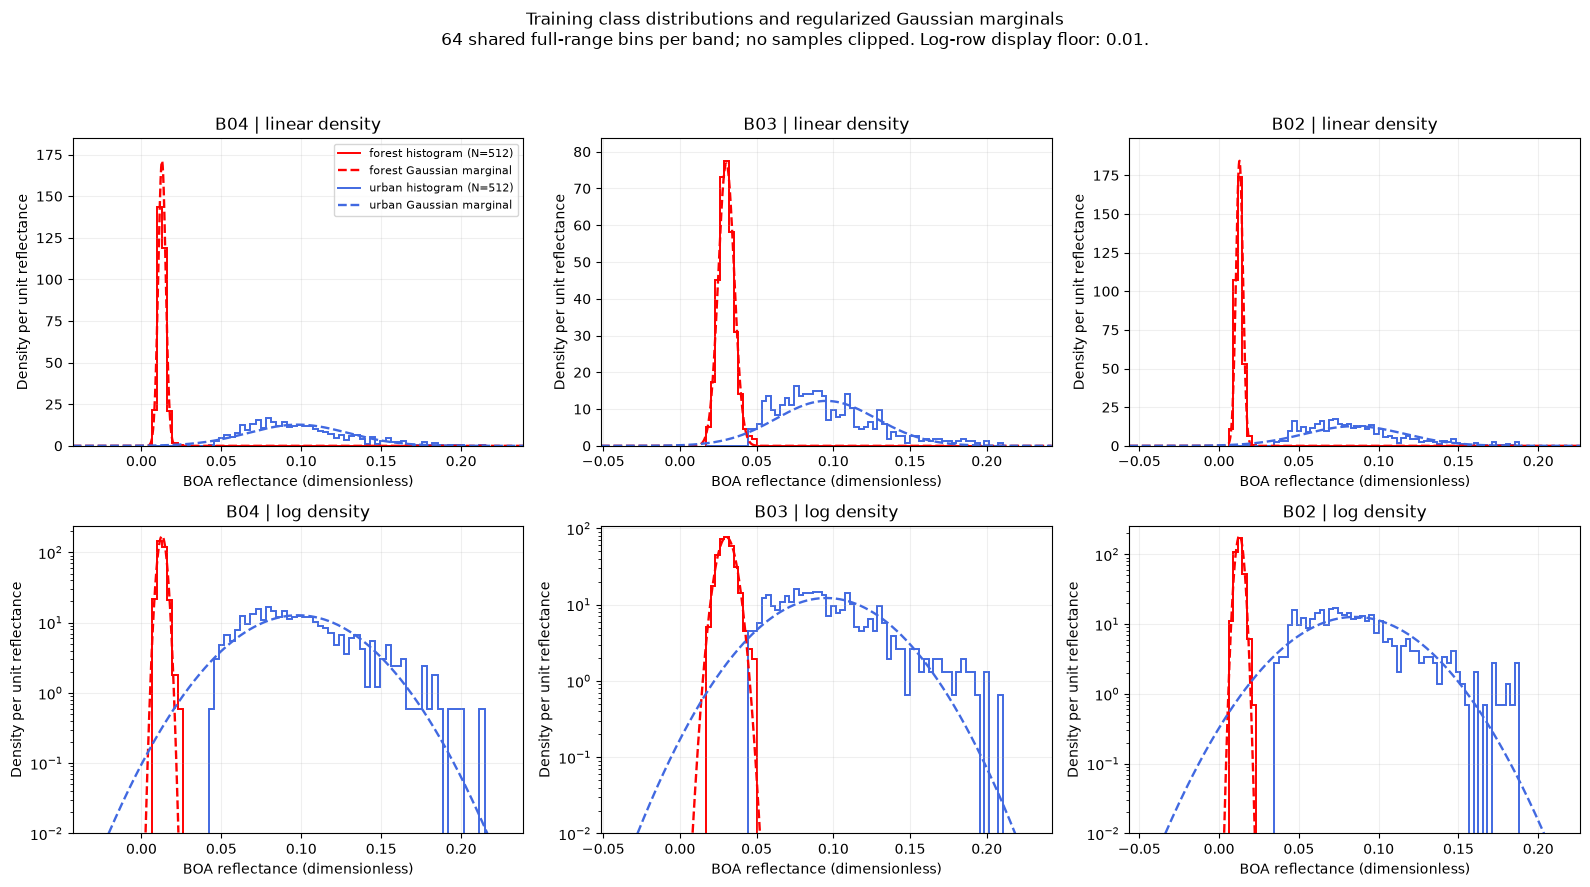

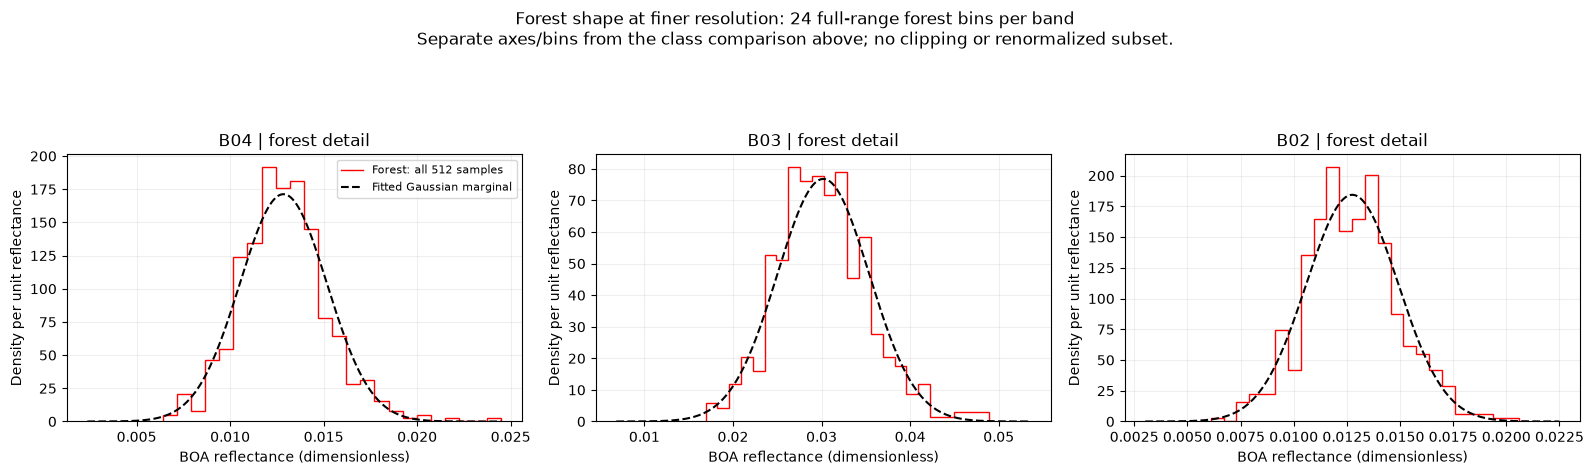

In [10]:
COLORS = ('red', 'royalblue')
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, band in enumerate(BANDS):
    spans = [(m['mean_raw'][j]-4.5*np.sqrt(m['cov_raw'][j,j]),
              m['mean_raw'][j]+4.5*np.sqrt(m['cov_raw'][j,j])) for m in model]
    left = min(X_raw[:,j].min(), *(p[0] for p in spans))
    right = max(X_raw[:,j].max(), *(p[1] for p in spans))
    grid = np.linspace(left, right, 6000)
    for row in (0, 1):
        ax = axes[row,j]
        peaks = []
        for m, color in zip(model, COLORS):
            h = histograms[(m['label'], band)]
            ax.stairs(h['density'], h['edges'], color=color, linewidth=1.4,
                      label=f"{m['name']} histogram (N={m['n']})")
            pdf = marginal_pdf(grid, m['mean_raw'][j], m['cov_raw'][j,j])
            visible_pdf = np.where(pdf >= 1e-2, pdf, np.nan) if row else pdf
            ax.plot(grid, visible_pdf, '--', color=color, linewidth=1.7, label=f"{m['name']} Gaussian marginal")
            peaks.extend([h['density'].max(), pdf.max()])
        ax.set_xlim(left, right)
        if row:
            ax.set_yscale('log')
            ax.set_ylim(1e-2, max(peaks)*1.4)
        else:
            ax.set_ylim(0, max(peaks)*1.08)
        ax.set_title(band + (' | linear density' if row == 0 else ' | log density'))
        ax.set_xlabel('BOA reflectance (dimensionless)')
        ax.set_ylabel('Density per unit reflectance')
        ax.grid(alpha=.2)
axes[0,0].legend(fontsize=8)
fig.suptitle('Training class distributions and regularized Gaussian marginals\n64 shared full-range bins per band; no samples clipped. Log-row display floor: 0.01.')
fig.tight_layout(rect=(0,0,1,.94))
fig.savefig(OUT / 'histograms_and_marginal_pdfs.png', dpi=170)
display(fig); plt.close(fig)

# Separate forest-only detail: full forest sample, finer bins, new axes.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
forest_detail = {}
m = model[0]
for j, (band, ax) in enumerate(zip(BANDS, axes)):
    values = X_raw[y_train == 0, j]
    edges = np.linspace(values.min(), values.max(), FOREST_DETAIL_BINS+1)
    counts, _ = np.histogram(values, bins=edges)
    density = counts/(len(values)*np.diff(edges))
    forest_detail[band] = dict(edges=edges, counts=counts, density=density)
    std = np.sqrt(m['cov_raw'][j,j])
    grid = np.linspace(min(values.min(), m['mean_raw'][j]-4.5*std),
                       max(values.max(), m['mean_raw'][j]+4.5*std), 3000)
    ax.stairs(density, edges, color='red', label='Forest: all 512 samples')
    ax.plot(grid, marginal_pdf(grid, m['mean_raw'][j], m['cov_raw'][j,j]),
            '--', color='black', label='Fitted Gaussian marginal')
    ax.set_title(band + ' | forest detail')
    ax.set_xlabel('BOA reflectance (dimensionless)')
    ax.set_ylabel('Density per unit reflectance')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle('Forest shape at finer resolution: 24 full-range forest bins per band\nSeparate axes/bins from the class comparison above; no clipping or renormalized subset.')
fig.tight_layout(rect=(0,0,1,.87))
fig.savefig(OUT / 'forest_marginal_detail.png', dpi=170)
display(fig); plt.close(fig)


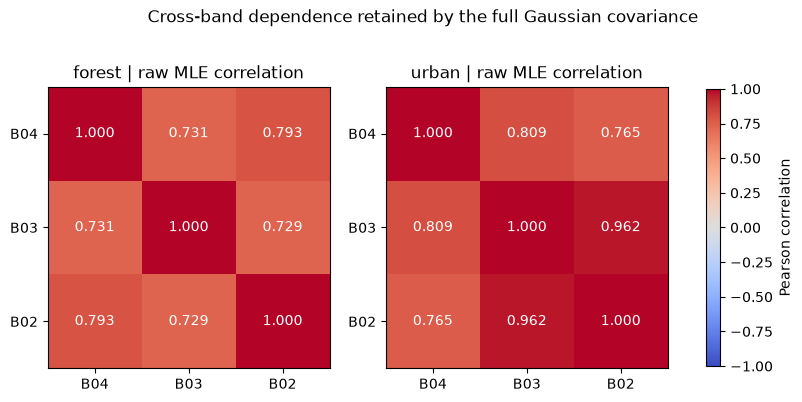

| Class | epsilon (scaled) | Smallest eigenvalue | Condition number | Max marginal variance increase | Max directional variance increase |
|---|---:|---:|---:|---:|---:|
| forest | 0e+00 | 0.000512191 | 38.40 | 0.0000% | 0.000% |
| forest | 1e-08 | 0.000512201 | 38.40 | 0.0004% | 0.002% |
| forest | 1e-06 | 0.000513191 | 38.32 | 0.0425% | 0.195% |
| forest | 1e-04 | 0.000612191 | 32.29 | 4.2452% | 19.524% |
| urban | 0e+00 | 0.021342 | 69.78 | 0.0000% | 0.000% |
| urban | 1e-08 | 0.0213421 | 69.78 | 0.0000% | 0.000% |
| urban | 1e-06 | 0.021343 | 69.78 | 0.0002% | 0.005% |
| urban | 1e-04 | 0.021442 | 69.46 | 0.0235% | 0.469% |

epsilon=1e-6 remains fixed; no test predictions or test-reference scores have been computed.


In [11]:
# Covariance structure and sensitivity are diagnostics, not hyperparameter tuning.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, m in zip(axes, model):
    im = ax.imshow(m['correlation'], vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(3), BANDS); ax.set_yticks(range(3), BANDS)
    ax.set_title(m['name'] + ' | raw MLE correlation')
    for row in range(3):
        for col in range(3):
            ax.text(col, row, f"{m['correlation'][row,col]:.3f}", ha='center', va='center',
                    color='white' if abs(m['correlation'][row,col]) > .65 else 'black')
fig.colorbar(im, ax=axes, label='Pearson correlation', shrink=.8)
fig.suptitle('Cross-band dependence retained by the full Gaussian covariance')
fig.savefig(OUT / 'band_correlations.png', dpi=170, bbox_inches='tight')
display(fig); plt.close(fig)
table = ['| Class | epsilon (scaled) | Smallest eigenvalue | Condition number | Max marginal variance increase | Max directional variance increase |',
         '|---|---:|---:|---:|---:|---:|']
for row in sensitivity:
    table.append(f"| {row['class_name']} | {row['epsilon']:.0e} | {row['min_eigenvalue']:.6g} | {row['condition_number']:.2f} | {row['max_marginal_variance_increase_percent']:.4f}% | {row['max_directional_variance_increase_percent']:.3f}% |")
display(Markdown('\n'.join(table)))
print('epsilon=1e-6 remains fixed; no test predictions or test-reference scores have been computed.')


In [12]:
# Portable model, histogram data and run settings for later Bayes prediction.
def write_csv(path, rows):
    rows = list(rows)
    with path.open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]), lineterminator='\n')
        writer.writeheader()
        writer.writerows(rows)

write_csv(OUT / 'summary.csv', summary_rows)
write_csv(OUT / 'histogram_overlap.csv', overlap)
write_csv(OUT / 'regularization_sensitivity.csv', sensitivity)
parameter_rows = []
covariance_rows = []
model_json = []
for m in model:
    model_json.append({key: value.tolist() if isinstance(value, np.ndarray) else value
                       for key, value in m.items()})
    for j, band in enumerate(BANDS):
        parameter_rows.append(dict(class_name=m['name'], band=band, n=m['n'], prior=m['prior'],
                                   mean_raw=float(m['mean_raw'][j]), mean_scaled=float(m['mean_z'][j]),
                                   std_raw_mle=float(np.sqrt(m['cov_raw_mle'][j,j])),
                                   std_raw_regularized=float(np.sqrt(m['cov_raw'][j,j]))))
    for units, mle, regularized in (('reflectance_squared', m['cov_raw_mle'], m['cov_raw']),
                                    ('standardized_squared', m['cov_z_mle'], m['cov_z'])):
        for kind, matrix in (('MLE_N_denominator', mle), ('regularized', regularized)):
            for j, band in enumerate(BANDS):
                covariance_rows.append(dict(class_name=m['name'], units=units, estimator=kind, row_band=band,
                                             **{col: float(matrix[j,k]) for k, col in enumerate(BANDS)}))
write_csv(OUT / 'parameters.csv', parameter_rows)
write_csv(OUT / 'covariances.csv', covariance_rows)
for (label, band), h in histograms.items():
    j = BANDS.index(band)
    m = model[label]
    centers = (h['edges'][:-1]+h['edges'][1:])/2
    pdf = marginal_pdf(centers, m['mean_raw'][j], m['cov_raw'][j,j])
    write_csv(OUT / f"{m['name']}_{band}_histogram.csv",
              [dict(left=float(a), right=float(b), count=int(c), density=float(d), gaussian_marginal_at_center=float(p))
               for a,b,c,d,p in zip(h['edges'][:-1], h['edges'][1:], h['counts'], h['density'], pdf)])
for band, h in forest_detail.items():
    write_csv(OUT / f'forest_{band}_detail_histogram.csv',
              [dict(left=float(a), right=float(b), count=int(c), density=float(d))
               for a,b,c,d in zip(h['edges'][:-1], h['edges'][1:], h['counts'], h['density'])])

model_settings = dict(schema_version=1, bands=list(BANDS), class_order=list(CLASS_NAMES),
                      model_family='full multivariate Gaussian', fit_space='standardized training features',
                      covariance_denominator='N_c (maximum likelihood)', regularization_scaled=REGULARIZATION,
                      regularization_rule='Sigma_scaled = Sigma_scaled_MLE + epsilon * I',
                      raw_covariance_rule='Sigma_raw = diag(training_scale) @ Sigma_scaled @ diag(training_scale)',
                      raw_density_jacobian='p_raw(x|c) = p_scaled((x-training_mean)/training_scale|c) / product(training_scale)',
                      prior_interpretation='equal priors by lab design; not estimated real-world area proportions',
                      scaling_mean=scaling_mean.tolist(), scaling_scale=scaling_scale.tolist(), classes=model_json)
lab3_inputs.dump(OUT / 'gaussian_model.json', model_settings)
np.savez_compressed(OUT / 'gaussian_model.npz',
                    class_ids=np.arange(2), class_names=np.array(CLASS_NAMES), bands=np.array(BANDS), priors=PRIORS,
                    means_scaled=np.stack([m['mean_z'] for m in model]),
                    covariances_scaled_mle=np.stack([m['cov_z_mle'] for m in model]),
                    covariances_scaled=np.stack([m['cov_z'] for m in model]),
                    means_raw=np.stack([m['mean_raw'] for m in model]),
                    covariances_raw_mle=np.stack([m['cov_raw_mle'] for m in model]),
                    covariances_raw=np.stack([m['cov_raw'] for m in model]),
                    scaling_mean=scaling_mean, scaling_scale=scaling_scale,
                    regularization_scaled=np.array(REGULARIZATION))
run_settings = dict(phase=2, training_samples=1024, per_class=512, seed=manifest['seed'],
                    input_hashes={str(path.relative_to(ROOT)): lab3_inputs.digest(path) for path in
                                  (lab3_inputs.DATA / 'training_samples.npz', lab3_inputs.DATA / 'scaling.json',
                                   lab3_inputs.DATA / 'manifest.json', ROOT / 'lab3/rois.json')},
                    histogram_bins_shared_per_band=HIST_BINS, forest_detail_bins_per_band=FOREST_DETAIL_BINS,
                    histogram_normalization='counts / (N_class * bin_width); every sample included',
                    plot_axes='raw reflectance; common class axes per band; forest-only detail has separate axes/bins',
                    log_density_display_floor=1e-2, regularization_scaled=REGULARIZATION,
                    sensitivity_epsilons=[0.0, 1e-8, REGULARIZATION, 1e-4],
                    holdout_and_test_used_for_fit=False, versions=phase1_verification['versions'])
lab3_inputs.dump(OUT / 'run_metadata.json', run_settings)
print('Saved model JSON/NPZ, six parameter rows, full covariance matrices, six shared-bin')
print('histograms, three forest-detail histograms, descriptive diagnostics and run settings.')
display(Markdown('| Class / band | Mean reflectance | MLE std | Prior |\n|---|---:|---:|---:|\n' +
    '\n'.join(f"| {r['class_name']} / {r['band']} | {r['mean_raw']:.6f} | {r['std_raw_mle']:.6f} | {r['prior']:.1f} |"
              for r in parameter_rows)))

Saved model JSON/NPZ, six parameter rows, full covariance matrices, six shared-bin
histograms, three forest-detail histograms, descriptive diagnostics and run settings.


| Class / band | Mean reflectance | MLE std | Prior |
|---|---:|---:|---:|
| forest / B04 | 0.012847 | 0.002329 | 0.5 |
| forest / B03 | 0.030196 | 0.005193 | 0.5 |
| forest / B02 | 0.012755 | 0.002163 | 0.5 |
| urban / B04 | 0.097916 | 0.031328 | 0.5 |
| urban / B03 | 0.095404 | 0.032642 | 0.5 |
| urban / B02 | 0.084926 | 0.031380 | 0.5 |

In [13]:
# Numerical and lossless-export checks against independent calculations.
tiny_mean, tiny_cov = gaussian_mle(np.array([[0.,0.], [2.,0.], [0.,2.], [2.,2.]]))
np.testing.assert_array_equal(tiny_mean, [1.,1.])
np.testing.assert_array_equal(tiny_cov, np.eye(2))  # N denominator: N-1 would yield 4/3 I.
saved_json = json.loads((OUT / 'gaussian_model.json').read_text())
saved_npz = np.load(OUT / 'gaussian_model.npz')
assert np.isclose(PRIORS.sum(), 1) and np.all(PRIORS > 0)
assert saved_json == model_settings
marginal_checks = []
for m in model:
    raw = X_raw[y_train == m['label']]
    np.testing.assert_allclose(m['mean_raw'], raw.mean(axis=0), atol=1e-14, rtol=1e-12)
    np.testing.assert_allclose(m['cov_raw_mle'], np.cov(raw, rowvar=False, bias=True), atol=1e-16, rtol=1e-12)
    np.testing.assert_allclose(m['cov_raw']-m['cov_raw_mle'],
                               np.diag(REGULARIZATION*scaling_scale**2), atol=1e-16, rtol=1e-8)
    for field, expected in (('means_raw', m['mean_raw']), ('means_scaled', m['mean_z']),
                            ('covariances_raw', m['cov_raw']), ('covariances_scaled', m['cov_z']),
                            ('covariances_raw_mle', m['cov_raw_mle']), ('covariances_scaled_mle', m['cov_z_mle'])):
        np.testing.assert_array_equal(saved_npz[field][m['label']], expected)
    for covariance in (m['cov_raw'], m['cov_z']):
        assert np.linalg.eigvalsh(covariance).min() > 0
        np.linalg.cholesky(covariance)
    for j, band in enumerate(BANDS):
        mean = m['mean_raw'][j]
        std = np.sqrt(m['cov_raw'][j,j])
        points = np.linspace(mean-10*std, mean+10*std, 20001)
        integral = float(np.trapezoid(marginal_pdf(points, mean, std**2), points))
        assert abs(integral-1) < 1e-10
        # The same marginal expressed in standardized units includes the density Jacobian.
        zpoints = (points-scaling_mean[j])/scaling_scale[j]
        np.testing.assert_allclose(marginal_pdf(points, mean, std**2),
                                   marginal_pdf(zpoints, m['mean_z'][j], m['cov_z'][j,j])/scaling_scale[j],
                                   rtol=1e-10, atol=1e-12)
        marginal_checks.append(dict(class_name=m['name'], band=band, integral_10sigma=integral,
                                    gaussian_mass_below_observed_min=float(ndtr((raw[:,j].min()-mean)/std)),
                                    gaussian_mass_above_observed_max=float(ndtr((mean-raw[:,j].max())/std))))
histogram_checks = 0
for path in sorted(OUT.glob('*_histogram.csv')):
    data = np.genfromtxt(path, delimiter=',', names=True)
    label = 0 if path.name.startswith('forest_') else 1
    band = path.name.split('_')[1]
    edges = np.r_[data['left'], data['right'][-1]]
    counts, _ = np.histogram(X_raw[y_train == label, BANDS.index(band)], bins=edges)
    np.testing.assert_array_equal(data['count'], counts)
    np.testing.assert_allclose(data['density'], counts/(512*np.diff(edges)), rtol=1e-12, atol=1e-12)
    assert counts.sum() == 512
    assert abs(np.dot(data['density'], np.diff(edges))-1) < 1e-12
    if 'gaussian_marginal_at_center' in data.dtype.names:
        m = model[label]; j = BANDS.index(band)
        np.testing.assert_allclose(data['gaussian_marginal_at_center'],
                                   marginal_pdf((data['left']+data['right'])/2, m['mean_raw'][j], m['cov_raw'][j,j]),
                                   rtol=1e-12, atol=1e-12)
    histogram_checks += 1
assert histogram_checks == 9
for row in np.genfromtxt(OUT / 'parameters.csv', delimiter=',', names=True, dtype=None, encoding='utf-8'):
    label, j = CLASS_NAMES.index(row['class_name']), BANDS.index(row['band'])
    assert row['mean_raw'] == model[label]['mean_raw'][j]
    assert row['prior'] == PRIORS[label] and row['n'] == 512
for row in np.genfromtxt(OUT / 'covariances.csv', delimiter=',', names=True, dtype=None, encoding='utf-8'):
    m = model[CLASS_NAMES.index(row['class_name'])]
    key = ('cov_raw' if row['units'] == 'reflectance_squared' else 'cov_z')
    key += '_mle' if row['estimator'] == 'MLE_N_denominator' else ''
    np.testing.assert_array_equal([row[band] for band in BANDS], m[key][BANDS.index(row['row_band'])])
for filename in ('histograms_and_marginal_pdfs.png', 'forest_marginal_detail.png', 'band_correlations.png'):
    with Image.open(OUT / filename) as scientific_figure:
        scientific_figure.verify()
lab3_inputs.dump(OUT / 'marginal_checks.json', marginal_checks)
verification = dict(status='passed', training_samples=1024, per_class=512,
                    histogram_exports_verified=histogram_checks, normalized_gaussian_marginals=6,
                    covariance_checks='raw/scaled MLE agreement; positive definite regularization; exact NPZ/JSON/CSV readback',
                    hand_calculated_mle_check='passed', training_density_jacobian_check='passed',
                    source_input_checks=lab3_inputs.verify()['status'],
                    output_sha256={str(path.relative_to(ROOT)): lab3_inputs.digest(path)
                                   for path in sorted(OUT.iterdir()) if path.is_file() and path.name not in
                                   ('verification.json', 'phase2_review.json')})
lab3_inputs.dump(OUT / 'verification.json', verification)
print('Phase 2:', verification['status'], '| normalized histograms:', histogram_checks,
      '| normalized Gaussian marginals:', len(marginal_checks))


Phase 2: passed | normalized histograms: 9 | normalized Gaussian marginals: 6


### Observations from these training samples

**Class separation and band differences.** Forest means in B04/B03/B02 are **0.012847 / 0.030196 / 0.012755**, compared with **0.097916 / 0.095404 / 0.084926** for urban. Forest green reflectance is higher than its red/blue reflectance, consistent with the displayed leafy canopy. The selected urban roofs and paved fabric are brighter on average in all three bands. Forest population standard deviations are **0.002329 / 0.005193 / 0.002163**; urban values are **0.031328 / 0.032642 / 0.031380**. Urban variation is about 6–15 times larger in standard-deviation terms, consistent with its mix of materials, illumination and shadows. These are plausible contributors, not controlled causal findings.

With the recorded 64 shared bins, empirical overlap is **0% (B04), 1.367% (B03), 0% (B02)**. Green's wider forest distribution reaches nearer the low urban tail. Zero occupied-bin overlap in this small, deliberately selected sample does not imply zero PDF overlap, perfect classification or reliable transfer to other scenes. The histogram overlap is bin-dependent and is not the multivariate Bayes error. The log-density row exposes low-probability bright urban tails hidden by the tall forest peak on linear axes.

**How well does a Gaussian fit?** Forest's finer histograms show one main approximately bell-shaped peak, but symmetry is imperfect: skewness is **0.523 / 0.397 / 0.223**, and excess kurtosis is **1.537 / 0.557 / 0.322**. In particular, B04 has a brighter tail beyond the symmetric fit. Urban distributions have a broad main concentration, irregular shoulders and long bright tails: skewness is **0.825 / 0.929 / 0.999**. The symmetric fitted urban curves put density into unobserved low-reflectance regions and tend to miss the upper tails. Several roof/pavement materials could create multiple subpopulations; jagged finite-sample histograms alone do not establish a particular number of modes. A single Gaussian is therefore a transparent baseline, not a demonstrated true class PDF. It has unbounded support; we neither truncate it to observed ranges nor clip input reflectance.

**The model is joint, the plotted curves are marginal.** Each dashed curve uses the corresponding regularized raw-unit variance. These plots do not assume band independence and cannot establish joint Gaussianity. Forest pairwise correlations are **0.729–0.793**, and urban correlations are **0.765–0.962** (green–blue is about **0.962**). The full 3 × 3 covariance retains this strong dependence; multiplying the three plotted marginal PDFs would instead impose an independence assumption and yield a different model.

**Regularization sensitivity.** Both unregularized training covariances are already positive definite. At the fixed epsilon **1e-6**, the largest relative marginal-variance increase is **0.0425% for forest** and **0.000235% for urban**. The largest directional increase (epsilon divided by the smallest original eigenvalue) is **0.195% / 0.00469%**, respectively. Thus this stabilization changes these fits only slightly. Epsilon **1e-4** would change the forest's smallest-direction variance by about **19.5%**, showing why regularization units and size matter. This is covariance sensitivity only; no classification result or test-label-based tuning has been performed.

**Priors and scope.** Equal priors express the planned balanced comparison, not measured class prevalence in Tychy. Sample locations, acquisition dates and manually selected interior ROIs remain confounded with class; the very small overlap can overstate performance on mixed pixels, other-cover areas or a new acquisition. The next phase must apply the saved joint model to the independent image and evaluate only against the reserved references.

Parameters and scaling are saved in [gaussian_model.json](results/bayes/gaussian_model.json) and [gaussian_model.npz](results/bayes/gaussian_model.npz); full-precision tables are [parameters.csv](results/bayes/parameters.csv) and [covariances.csv](results/bayes/covariances.csv). The figures, bin counts, moments, sensitivity diagnostics and [verification report](results/bayes/verification.json) are all retained under `results/bayes/`.

## 3. Implement and apply the Bayes classifier from scratch

For equal misclassification costs, Bayes' rule gives
$$P(c\mid z)=\frac{p(z\mid c)P(c)}{\sum_j p(z\mid j)P(j)}.$$
The evidence in the denominator is identical for both classes. Therefore choose the class maximizing
$$g_c(z)=\log P(c)-\tfrac12\left[3\log(2\pi)+\log|\Sigma_c|+(z-\mu_c)^T\Sigma_c^{-1}(z-\mu_c)\right].$$
The saved phase-2 model uses full covariance, equal priors, and $10^{-6}I$ regularization in standardized coordinates. These settings and the training-only mean/scale remain fixed.

[bayes.py](bayes.py) implements fitting and prediction using NumPy. With $\Sigma_c=L_cL_c^T$, it computes $\log|\Sigma_c|=2\sum_j\log L_{c,jj}$ and the quadratic term as $\|L_c^{-1}(z-\mu_c)\|^2$, using a linear solve. No inverse, product of marginal PDFs, or ready-made classifier is used. Exact equal scores choose the **smaller class ID (forest = 0)**; no approximate tie tolerance is applied.

Acceptance: classify every QA-valid Tychy pixel, preserve nodata=255, verify finite scores and agreement with analytical/independent score calculations, save a georeferenced lossless raster and separate red/blue image, and inspect matched image/map detail. Reserved reference labels are used only after prediction to describe observed agreement/errors; parameters and ROIs are not tuned from the result.

In [14]:
from bayes import GaussianBayes
import rasterio
from matplotlib.patches import Patch, Rectangle
CLASSIFY_OUT = OUT / 'classification'
CLASSIFY_OUT.mkdir(parents=True, exist_ok=True)
saved_model = np.load(OUT / 'gaussian_model.npz')
bayes_classifier = GaussianBayes(saved_model['class_ids'], saved_model['means_scaled'],
                                 saved_model['covariances_scaled'], saved_model['priors'])
# Cross-check scratch fitting against phase 2; use the saved model for prediction.
refitted = GaussianBayes.fit(X_train, y_train, priors=saved_model['priors'],
                            regularization=float(saved_model['regularization_scaled']))
np.testing.assert_array_equal(refitted.classes, bayes_classifier.classes)
np.testing.assert_array_equal(refitted.means, bayes_classifier.means)
np.testing.assert_array_equal(refitted.covariances, bayes_classifier.covariances)
np.testing.assert_array_equal(saved_model['scaling_mean'], scaling_mean)
np.testing.assert_array_equal(saved_model['scaling_scale'], scaling_scale)
assert saved_model['bands'].tolist() == list(BANDS)
test_source = sources['tychy']
test_valid = test_source['valid']
test_features = X_test_scaled[test_valid]
BAYES_BATCH_SIZE = 8192
test_predictions = bayes_classifier.predict(test_features, batch_size=BAYES_BATCH_SIZE)
test_log_scores = bayes_classifier.log_scores(test_features)
class_map = np.full(test_valid.shape, 255, dtype=np.uint8)
class_map[test_valid] = test_predictions
assert np.isin(class_map[test_valid], [0,1]).all()
assert np.all(class_map[~test_valid] == 255)
map_counts = {name: int(np.count_nonzero(class_map == label)) for label, name in enumerate(CLASS_NAMES)}
map_counts['nodata'] = int(np.count_nonzero(~test_valid))
print('Tychy classified pixels:', int(test_valid.sum()), '| map counts:', map_counts)
print('Log-score ranges, forest / urban:', test_log_scores.min(axis=0), test_log_scores.max(axis=0))
print('Exact score ties:', int(np.count_nonzero(test_log_scores[:,0] == test_log_scores[:,1])))


Tychy classified pixels: 261648 | map counts: {'forest': 10487, 'urban': 251161, 'nodata': 496}
Log-score ranges, forest / urban: [-71992.82811201   -231.36608137] [ 4.63249727 -0.68980361]
Exact score ties: 0


In [15]:
# Lossless class IDs with source georeferencing; transparent RGBA for nodata.
palette = np.zeros((256, 4), dtype=np.uint8)
palette[0] = [255, 0, 0, 255]  # forest = red
palette[1] = [0, 0, 255, 255]  # urban = blue
palette[255] = [128, 128, 128, 0]
rgba_map = palette[class_map]
profile = test_source['profile'].copy()
profile.update(count=1, dtype='uint8', nodata=255, compress='deflate')
with rasterio.open(CLASSIFY_OUT / 'tychy_bayes_classes.tif', 'w', **profile) as output:
    output.write(class_map, 1)
    output.set_band_description(1, '0 forest; 1 urban; 255 invalid/nodata')
    output.update_tags(classifier='scratch full Gaussian Bayes', class_0='forest/red', class_1='urban/blue',
                       source_scene=test_source['meta']['scene_id'], priors='0.5,0.5',
                       covariance_regularization_scaled='1e-6', exact_tie_rule='smaller class ID')
Image.fromarray(rgba_map).save(CLASSIFY_OUT / 'tychy_bayes_colors.png')
np.savez_compressed(CLASSIFY_OUT / 'tychy_bayes_scores.npz',
                    valid_flat_index=np.flatnonzero(test_valid), log_scores_scaled=test_log_scores,
                    class_order=saved_model['class_ids'])
print('Saved uint8 GeoTIFF, RGBA map and valid-pixel class log scores.')


Saved uint8 GeoTIFF, RGBA map and valid-pixel class log scores.


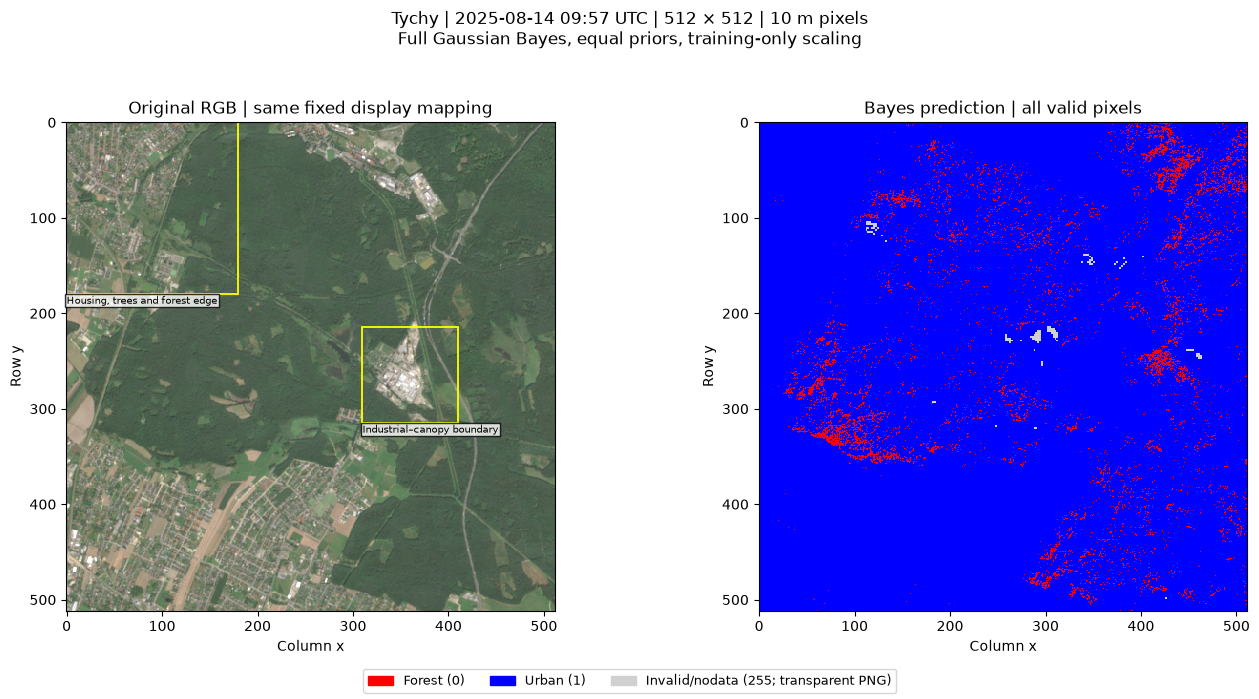

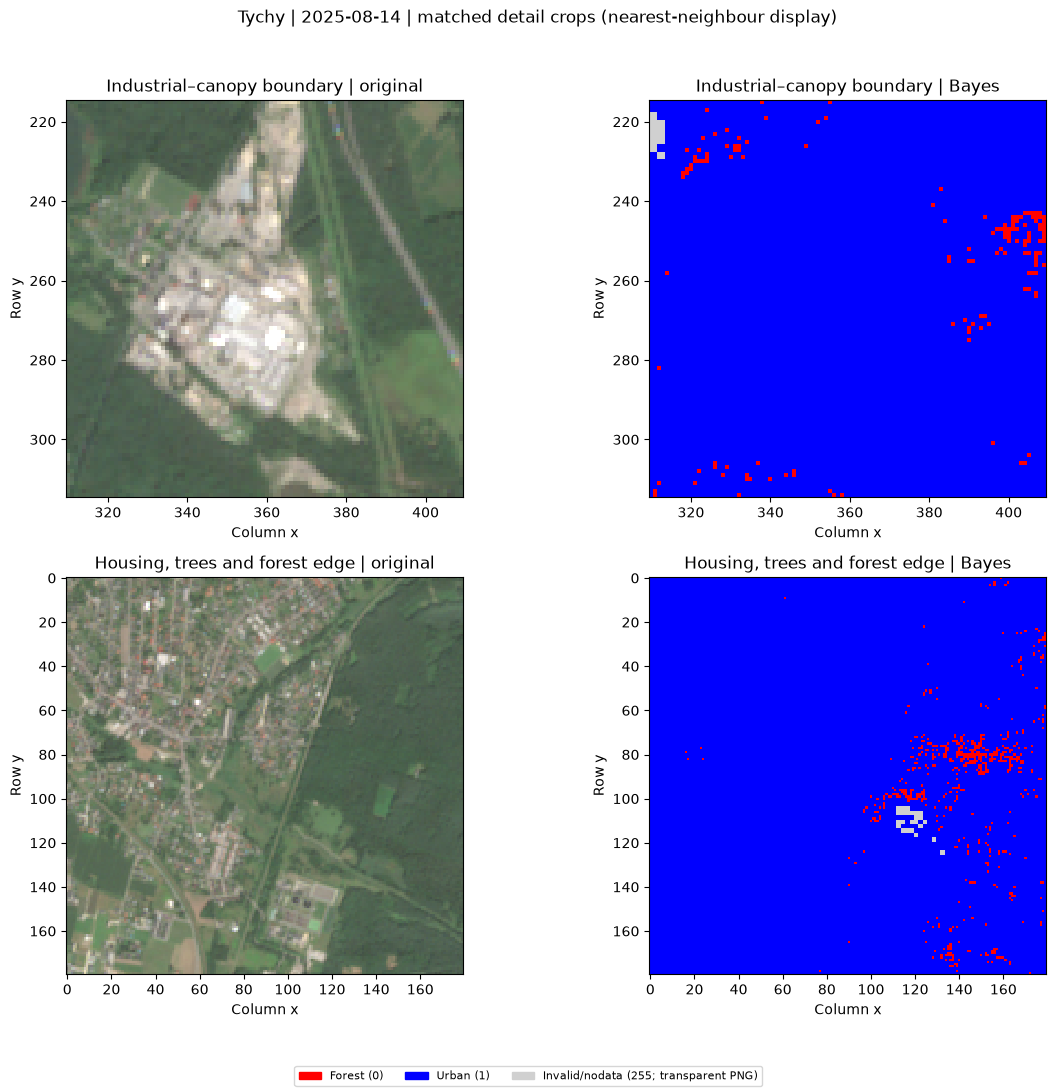

In [16]:
map_legend = [Patch(color='red', label='Forest (0)'), Patch(color='blue', label='Urban (1)'),
              Patch(color='#d0d0d0', label='Invalid/nodata (255; transparent PNG)')]
detail_boxes = {'Industrial–canopy boundary': [310, 215, 410, 315],
                'Housing, trees and forest edge': [0, 0, 180, 180]}
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    ax.set_facecolor('#d0d0d0')
axes[0].imshow(test_source['rgb'], interpolation='nearest')
axes[1].imshow(rgba_map, interpolation='nearest')
for name, box in detail_boxes.items():
    x0,y0,x1,y1 = box
    axes[0].add_patch(Rectangle((x0-.5,y0-.5),x1-x0,y1-y0, fill=False, edgecolor='yellow', linewidth=1.3))
    axes[0].text(x0, y1+10, name, fontsize=7, color='black', bbox=dict(facecolor='white', alpha=.8, pad=1))
axes[0].set_title('Original RGB | same fixed display mapping')
axes[1].set_title('Bayes prediction | all valid pixels')
for ax in axes:
    ax.set_xlabel('Column x'); ax.set_ylabel('Row y')
fig.legend(handles=map_legend, loc='lower center', ncol=3, fontsize=9)
fig.suptitle('Tychy | 2025-08-14 09:57 UTC | 512 × 512 | 10 m pixels\nFull Gaussian Bayes, equal priors, training-only scaling')
fig.tight_layout(rect=(0,.07,1,.92))
fig.savefig(CLASSIFY_OUT / 'tychy_bayes_comparison.png', dpi=170)
display(fig); plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for row, (name, box) in enumerate(detail_boxes.items()):
    x0,y0,x1,y1 = box
    extent = (x0-.5,x1-.5,y1-.5,y0-.5)
    axes[row,0].imshow(test_source['rgb'][y0:y1,x0:x1], extent=extent, interpolation='nearest')
    axes[row,1].imshow(rgba_map[y0:y1,x0:x1], extent=extent, interpolation='nearest')
    axes[row,0].set_title(name+' | original')
    axes[row,1].set_title(name+' | Bayes')
    for ax in axes[row]:
        ax.set_facecolor('#d0d0d0')
        ax.set_xlabel('Column x'); ax.set_ylabel('Row y')
fig.legend(handles=map_legend, loc='lower center', ncol=3, fontsize=8)
fig.suptitle('Tychy | 2025-08-14 | matched detail crops (nearest-neighbour display)')
fig.tight_layout(rect=(0,.05,1,.96))
fig.savefig(CLASSIFY_OUT / 'tychy_bayes_details.png', dpi=170)
display(fig); plt.close(fig)


In [17]:
# Reference agreement is descriptive, not a full-image accuracy estimate.
reference = label_masks['tychy']['test']
reference_valid = (reference != 255) & test_valid
reference_truth = reference[reference_valid]
reference_pred = class_map[reference_valid]
confusion = np.zeros((2,2), dtype=np.int64)  # rows = reference; columns = prediction
np.add.at(confusion, (reference_truth, reference_pred), 1)
roi_agreement = []
for roi in manifest['roi_counts']:
    if roi['source'] != 'tychy':
        continue
    x0,y0,x1,y1 = roi['box_xyxy']
    selected = test_valid[y0:y1,x0:x1] & (reference[y0:y1,x0:x1] == roi['label'])
    predicted = class_map[y0:y1,x0:x1][selected]
    roi_agreement.append(dict(roi_id=roi['id'], reference_class=CLASS_NAMES[roi['label']],
                              support=int(selected.sum()), predicted_forest=int(np.count_nonzero(predicted == 0)),
                              predicted_urban=int(np.count_nonzero(predicted == 1)),
                              correct=int(np.count_nonzero(predicted == roi['label']))))
write_csv(CLASSIFY_OUT / 'test_roi_agreement.csv', roi_agreement)
write_csv(CLASSIFY_OUT / 'test_reference_confusion.csv',
          [dict(reference_class=CLASS_NAMES[label], predicted_forest=int(confusion[label,0]),
                predicted_urban=int(confusion[label,1]), support=int(confusion[label].sum()))
           for label in range(2)])
table = ['| Reference class | Predicted forest | Predicted urban | Labelled support |',
         '|---|---:|---:|---:|']
for label, name in enumerate(CLASS_NAMES):
    table.append(f'| {name} | {confusion[label,0]} | {confusion[label,1]} | {confusion[label].sum()} |')
display(Markdown('\n'.join(table)))
print('Per-ROI reference evidence:', roi_agreement)
print('Only', int(reference_valid.sum()), 'of', int(test_valid.sum()), 'valid pixels have reference labels.')


| Reference class | Predicted forest | Predicted urban | Labelled support |
|---|---:|---:|---:|
| forest | 148 | 2156 | 2304 |
| urban | 0 | 256 | 256 |

Per-ROI reference evidence: [{'roi_id': 'T-F-t1', 'reference_class': 'forest', 'support': 576, 'predicted_forest': 47, 'predicted_urban': 529, 'correct': 47}, {'roi_id': 'T-F-t2', 'reference_class': 'forest', 'support': 576, 'predicted_forest': 5, 'predicted_urban': 571, 'correct': 5}, {'roi_id': 'T-F-t3', 'reference_class': 'forest', 'support': 576, 'predicted_forest': 82, 'predicted_urban': 494, 'correct': 82}, {'roi_id': 'T-F-t4', 'reference_class': 'forest', 'support': 576, 'predicted_forest': 14, 'predicted_urban': 562, 'correct': 14}, {'roi_id': 'T-U-t1', 'reference_class': 'urban', 'support': 64, 'predicted_forest': 0, 'predicted_urban': 64, 'correct': 64}, {'roi_id': 'T-U-t2', 'reference_class': 'urban', 'support': 64, 'predicted_forest': 0, 'predicted_urban': 64, 'correct': 64}, {'roi_id': 'T-U-t3', 'reference_class': 'urban', 'support': 64, 'predicted_forest': 0, 'predicted_urban': 64, 'correct': 64}, {'roi_id': 'T-U-t4', 'reference_class': 'urban', 'support': 64, 'predicted_

| Class / band | Training mean | Test-reference mean |
|---|---:|---:|
| forest / B04 | 0.012847 | 0.021900 |
| forest / B03 | 0.030196 | 0.035748 |
| forest / B02 | 0.012755 | 0.022850 |
| urban / B04 | 0.097916 | 0.194983 |
| urban / B03 | 0.095404 | 0.181253 |
| urban / B02 | 0.084926 | 0.164818 |

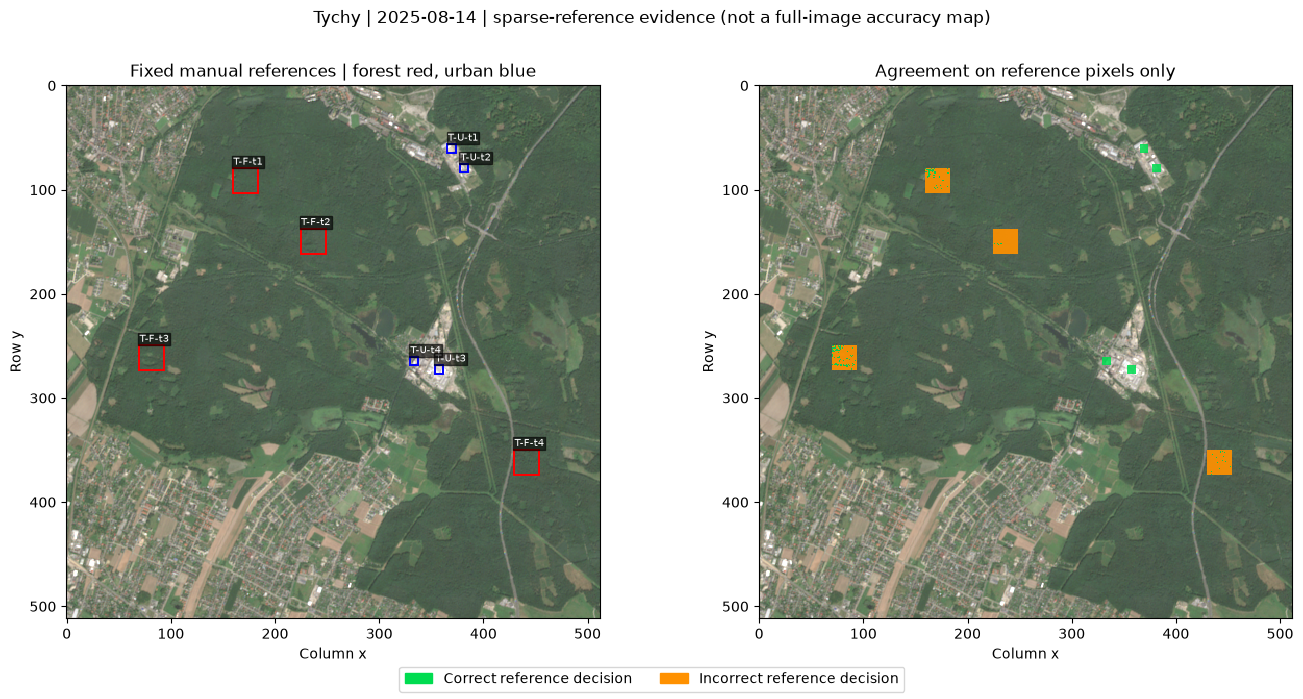

In [18]:
# Post-prediction diagnostic only: quantify the observed training/test feature shift.
feature_shift = []
for label, name in enumerate(CLASS_NAMES):
    test_rows = X_test_raw[(reference == label) & test_valid].astype(np.float64)
    train_rows = X_raw[y_train == label]
    for j, band in enumerate(BANDS):
        feature_shift.append(dict(class_name=name, band=band, test_reference_support=len(test_rows),
                                  train_mean=float(train_rows[:,j].mean()),
                                  test_reference_mean=float(test_rows[:,j].mean()),
                                  train_std=float(train_rows[:,j].std()),
                                  test_reference_std=float(test_rows[:,j].std())))
write_csv(CLASSIFY_OUT / 'test_reference_feature_summary.csv', feature_shift)
table = ['| Class / band | Training mean | Test-reference mean |',
         '|---|---:|---:|']
for row in feature_shift:
    table.append(f"| {row['class_name']} / {row['band']} | {row['train_mean']:.6f} | {row['test_reference_mean']:.6f} |")
display(Markdown('\n'.join(table)))
correct_reference = reference_valid & (class_map == reference)
incorrect_reference = reference_valid & (class_map != reference)
agreement_overlay = np.zeros((*class_map.shape, 4), dtype=np.uint8)
agreement_overlay[correct_reference] = [0, 220, 80, 220]
agreement_overlay[incorrect_reference] = [255, 145, 0, 235]
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax in axes:
    ax.imshow(test_source['rgb'], interpolation='nearest')
    ax.set_xlabel('Column x'); ax.set_ylabel('Row y')
for roi in manifest['roi_counts']:
    if roi['source'] == 'tychy':
        x0,y0,x1,y1 = roi['box_xyxy']
        axes[0].add_patch(Rectangle((x0-.5,y0-.5),x1-x0,y1-y0, fill=False,
                                   edgecolor='red' if roi['label'] == 0 else 'blue', linewidth=1.4))
        axes[0].text(x0, y0-4, roi['id'], fontsize=7, color='white',
                     bbox=dict(facecolor='black', alpha=.6, pad=1))
axes[1].imshow(agreement_overlay, interpolation='nearest')
axes[0].set_title('Fixed manual references | forest red, urban blue')
axes[1].set_title('Agreement on reference pixels only')
fig.legend(handles=[Patch(color='#00dc50', label='Correct reference decision'),
                    Patch(color='#ff9100', label='Incorrect reference decision')],
           loc='lower center', ncol=2)
fig.suptitle('Tychy | 2025-08-14 | sparse-reference evidence (not a full-image accuracy map)')
fig.tight_layout(rect=(0,.06,1,.94))
fig.savefig(CLASSIFY_OUT / 'tychy_bayes_reference_agreement.png', dpi=170)
display(fig); plt.close(fig)


In [19]:
# Hand-computed 1D case exercises normalization, log determinant and Mahalanobis distance.
hand = GaussianBayes([0,1], [[0.],[2.]], [[[1.]],[[4.]]], [.5,.5])
base = np.log(.5) - .5*np.log(2*np.pi)
expected_scores = np.array([[base, base-np.log(2)-.5], [base-2, base-np.log(2)]])
np.testing.assert_allclose(hand.log_scores([[0.],[2.]]), expected_scores, rtol=0, atol=1e-14)
np.testing.assert_array_equal(hand.predict([[0.],[2.]]), [0,1])
tie_model = GaussianBayes([0,1], [[-1.],[1.]], [[[1.]],[[1.]]], [.5,.5])
assert tie_model.log_scores([[0.]])[0,0] == tie_model.log_scores([[0.]])[0,1]
np.testing.assert_array_equal(tie_model.predict([[0.]]), [0])
# Unequal priors must affect decisions when the class-conditional densities are identical.
prior_model = GaussianBayes([0,1], [[0.],[0.]], [[[1.]],[[1.]]], [.2,.8])
np.testing.assert_array_equal(prior_model.predict([[0.],[2.]]), [1,1])
# Independent NumPy slogdet/direct covariance solve; compare all valid-pixel scores.
independent_scores = np.empty_like(test_log_scores)
for col in range(2):
    covariance = saved_model['covariances_scaled'][col]
    sign, logdet = np.linalg.slogdet(covariance)
    assert sign == 1
    delta = test_features - saved_model['means_scaled'][col]
    quadratic = np.sum(delta*np.linalg.solve(covariance, delta.T).T, axis=1)
    independent_scores[:,col] = np.log(saved_model['priors'][col]) - .5*(3*np.log(2*np.pi)+logdet+quadratic)
np.testing.assert_allclose(test_log_scores, independent_scores, rtol=1e-11, atol=1e-9)
np.testing.assert_array_equal(test_predictions, saved_model['class_ids'][np.argmax(independent_scores,axis=1)])
np.testing.assert_array_equal(test_predictions, bayes_classifier.predict(test_features, batch_size=1009))
# Raw-space scores differ by the shared density Jacobian; predictions must agree.
raw_classifier = GaussianBayes(saved_model['class_ids'], saved_model['means_raw'],
                               saved_model['covariances_raw'], saved_model['priors'])
raw_scores = raw_classifier.log_scores(X_test_raw[test_valid])
np.testing.assert_allclose(raw_scores, test_log_scores-np.log(scaling_scale).sum(), rtol=1e-10, atol=1e-8)
np.testing.assert_array_equal(raw_classifier.predict(X_test_raw[test_valid]), test_predictions)
with rasterio.open(CLASSIFY_OUT / 'tychy_bayes_classes.tif') as saved_raster:
    np.testing.assert_array_equal(saved_raster.read(1), class_map)
    np.testing.assert_array_equal(saved_raster.read_masks(1) != 0, test_valid)
    assert saved_raster.crs == test_source['profile']['crs']
    assert saved_raster.transform == test_source['profile']['transform']
    assert saved_raster.shape == class_map.shape and saved_raster.nodata == 255
    assert saved_raster.dtypes == ('uint8',) and saved_raster.count == 1
np.testing.assert_array_equal(np.array(Image.open(CLASSIFY_OUT / 'tychy_bayes_colors.png')), rgba_map)
assert np.all(rgba_map[class_map == 0] == [255,0,0,255])
assert np.all(rgba_map[class_map == 1] == [0,0,255,255])
assert np.all(rgba_map[~test_valid,3] == 0)
with np.load(CLASSIFY_OUT / 'tychy_bayes_scores.npz') as saved_scores:
    np.testing.assert_array_equal(saved_scores['valid_flat_index'], np.flatnonzero(test_valid))
    np.testing.assert_array_equal(saved_scores['log_scores_scaled'], test_log_scores)
    np.testing.assert_array_equal(saved_scores['class_order'], [0,1])
assert confusion.sum() == reference_valid.sum() == 2560
assert sum(row['correct'] for row in roi_agreement) == np.trace(confusion)
saved_confusion = np.genfromtxt(CLASSIFY_OUT / 'test_reference_confusion.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
np.testing.assert_array_equal([[r['predicted_forest'], r['predicted_urban']] for r in saved_confusion], confusion)
for filename in ('tychy_bayes_comparison.png', 'tychy_bayes_details.png', 'tychy_bayes_reference_agreement.png'):
    with Image.open(CLASSIFY_OUT / filename) as rendered:
        rendered.verify()
classification_metadata = dict(phase=3, source='tychy', scene_id=test_source['meta']['scene_id'],
    acquired_utc=test_source['meta']['acquired_utc'], band_order=list(BANDS),
    model='full Gaussian Bayes', priors=saved_model['priors'].tolist(),
    regularization_scaled=float(saved_model['regularization_scaled']),
    class_ids={'forest':0, 'urban':1, 'nodata':255}, colors={'forest':'red', 'urban':'blue', 'nodata':'transparent'},
    exact_tie_rule='smaller class ID; no tolerance', score_space='standardized features',
    score_definition='log p(z|class) + log prior; not normalized posterior probabilities',
    batch_size=BAYES_BATCH_SIZE, detail_boxes_xyxy=detail_boxes,
    valid_pixels=int(test_valid.sum()), map_counts=map_counts,
    test_reference_confusion_rows_truth_columns_prediction=confusion.tolist(),
    reference_support=int(reference_valid.sum()), reference_used_to_tune_model=False,
    input_hashes={str(path.relative_to(ROOT)): lab3_inputs.digest(path) for path in
        (ROOT/'lab3/bayes.py', OUT/'gaussian_model.npz', OUT/'gaussian_model.json',
         lab3_inputs.DATA/'manifest.json', lab3_inputs.DATA/'scaling.json',
         lab3_inputs.DATA/'labels/tychy/test_labels.tif', lab3_inputs.DATA/'labels/tychy/valid_mask.tif',
         lab3_inputs.SOURCE_DIRS['tychy']/'rgb_reflectance.tif')},
    versions=phase1_verification['versions'])
lab3_inputs.dump(CLASSIFY_OUT / 'run_metadata.json', classification_metadata)
classification_verification = dict(status='passed', valid_pixels=int(test_valid.sum()), nodata_pixels=int((~test_valid).sum()),
    finite_log_scores=bool(np.isfinite(test_log_scores).all()), hand_calculated_score_and_tie_checks='passed',
    unequal_prior_check='passed', full_image_independent_score_check='passed', batch_invariance_check='passed',
    raw_scaled_score_jacobian_and_prediction_check='passed', lossless_raster_png_score_readback='passed',
    reference_confusion_and_roi_counts='passed',
    output_sha256={str(path.relative_to(ROOT)): lab3_inputs.digest(path) for path in sorted(CLASSIFY_OUT.iterdir())
                   if path.is_file() and path.name not in ('verification.json','phase3_review.json')})
lab3_inputs.dump(CLASSIFY_OUT / 'verification.json', classification_verification)
print('Phase 3 verification:', classification_verification['status'])
print('Classified:', int(test_valid.sum()), '| preserved nodata:', int((~test_valid).sum()))


Phase 3 verification: passed
Classified: 261648 | preserved nodata: 496


### Observations: a numerically correct baseline that transfers poorly

**What the map actually shows.** Every one of the **261,648 valid pixels** receives a binary decision: **10,487 forest (4.01%)** and **251,161 urban (95.99%)**. The **496 invalid pixels** stay nodata/transparent and appear neutral grey on the plotted maps. These predicted fractions are not measured land-cover proportions. The RGB image contains extensive forest, yet the prediction is overwhelmingly blue. Isolated red patches do not reconstruct continuous canopy boundaries.

**Successes and errors supported by the reserved labels.** All **256/256 industrial urban reference pixels** are predicted urban. Only **148/2,304 forest reference pixels (6.42%)** are predicted forest; **2,156** are assigned urban. Each of the four forest ROIs has many errors (529, 571, 494 and 562 pixels, respectively). The agreement overlay shows those failures directly. This is strong evidence of poor forest transfer in the selected ROIs, despite easy separation of the original training samples. Only **2,560 pixels** carry reference labels; the industrial urban references are deliberately clear interiors, so their perfect agreement cannot establish accuracy for all housing, roads or urban vegetation.

**Why this can happen.** After prediction, the labelled Tychy forest means are B04/B03/B02 = **0.021900 / 0.035748 / 0.022850**, versus **0.012847 / 0.030196 / 0.012755** in Białowieża training. The red and blue shifts are several within-training-class standard deviations. The narrow forest Gaussian strongly penalizes these shifted spectra, while the broader urban model wins the relative likelihood comparison. Tychy's industrial references are also brighter than the Kraków examples. This feature-shift evidence supports a generalization problem; it does not isolate its causes. Location, canopy composition, July versus August acquisition, satellite/illumination differences and residual atmospheric effects may contribute. Source calibration, input masks and training-only scaling were verified, and no per-test-image stretch was introduced.

**Reading the detail crops.** The industrial structures are blue, but most adjacent canopy is blue too; the apparent urban success therefore does not mean the land-cover boundary is recovered. Housing, gardens and forest edges in the northwest are also mostly blue. Some darker canopy pixels become red, but no independent shadow labels exist here, so shadow-specific correctness cannot be quantified. At 10 m, mixed building/tree/soil pixels and trees within urban fabric violate a pure two-class interpretation. Fields, grass and other unlabelled covers are also forced to forest or urban: blue fields cannot be interpreted as validated urban detections. Nodata holes are excluded QA pixels, not classification errors.

**Verification versus accuracy.** The implementation passes hand-calculated Gaussian scores, exact ties, unequal priors, independent full-image log-score calculations, batch invariance, raw/scaled density conversion, and lossless raster/PNG/score readback. This verifies the specified Bayes calculation, not usefulness of its learned distributions. The saved log scores are unnormalized log joint densities, not calibrated confidence values. We preserve the fixed phase-2 model and original references so later kNN comparison uses the same inputs and this honest baseline.

Outputs: [full comparison](results/bayes/classification/tychy_bayes_comparison.png), [detail crops](results/bayes/classification/tychy_bayes_details.png), [reference agreement](results/bayes/classification/tychy_bayes_reference_agreement.png), [class GeoTIFF](results/bayes/classification/tychy_bayes_classes.tif), [coloured PNG](results/bayes/classification/tychy_bayes_colors.png), and [verification](results/bayes/classification/verification.json).

## 4. Implement kNN from scratch and run k = 1, 3, 5

Pending: explicit distances, stable neighbour selection, majority voting and three comparable maps.

## 5. Compare results and explain the effect of k

Pending: common-reference metrics, disagreement evidence and observations for each k.

## 6. Final notebook and submission checks

Pending: full-lab validation, final review and portable archive. The phase-1 verification above covers data preparation only.